# YOLO11s P2: scale and brightness robustness check (pipeline, tuned)

## Overview

Parent run: `yolo11s-p2-combined` (C4 in `SCOPE.md`). This notebook trains nothing. It loads the saved `best.pt` of two finished runs, C4 and its parent T7 `yolo11s-1280-p2`, and predicts the same val frames under six input conditions. It is the check planned before X1 `pipeline-final` (`SCOPE.md` open decision 17). Inference runs on the Kaggle T4 GPU (`DEVICE = 0`) in fp32, as in every evaluation.

**Question.** C4 is 0.0200 mAP@500 above T7 on full val (0.2365 vs 0.2165) and 0.0727 above it on the public LB (0.28689 vs 0.21419). LB − val is +0.0504 for C4 and −0.0023 for T7 (`EXPERIMENTS.md`, `SCOPE.md` F92–F93). C4 changed seven settings at once. Two of them target test conditions that no labelled clip has:
- `SCALE = (0.5, 2.0)`: 8 test clips are 680×382 or 960×540, smaller than any labelled clip (the smallest is 1344×756). At `imgsz = 1280` they are upscaled by 1.88 and 1.33 (`EDA.md` §5, F9).
- `HSV_V = 0.7`: most clips have a mean grey value of 90–140, and at least one test clip lies in the 20–30 bin, darker than any labelled clip (`EDA.md` §9, F13).

The notebook measures how much each model loses when val frames are made to look like those test clips. It cannot say which of the seven changes causes a difference; it only tests whether these two conditions separate the two checkpoints.

**Views** (input conditions, identical for both models):

| View | Transform of a val frame |
|---|---|
| `original` | none |
| `width_960` | resized to 960 px width, aspect ratio kept (960×540 for a 16:9 frame) |
| `width_680` | resized to 680 px width (680×382 for a 16:9 frame) |
| `brightness_0.5` | every RGB value multiplied by 0.5 |
| `brightness_0.25` | every RGB value multiplied by 0.25 (a clip with mean grey 100 becomes 25) |
| `width_680_brightness_0.25` | both |

Resizing is antialiased bilinear interpolation (torchvision). Multiplying R, G and B by one factor multiplies the HSV value channel by that factor and leaves hue and saturation unchanged, which is the kind of change Ultralytics' `hsv_v` augmentation makes. The view is then letterboxed to `IMAGE_SIZE` by Ultralytics, as a test frame of that size would be. Predicted boxes are mapped back to the original frame with the inverse scale factors and evaluated against the unchanged val GT, so IoU and the COCO size buckets are in original pixels.

**Frames.** The check frames are every 5th val frame at offset 2 in each clip (frame index ≡ 2 mod 5), 571 frames from all 7 clips. They do not overlap the quick-val frames (offset 0), on which both checkpoints were selected. The 4K clip `uav0000268_05773_v` contributes 196 of the 571 frames. Downscaling it to 680 px shrinks it 5.6 times, which no test clip needs (no test clip is wider than 1920 px), so every view is also reported without that clip (`mAP_without_4k`).

**How to read the results.** The quantities of interest are the drop of each model from its own `original` row (`delta_vs_original`) and the C4 − T7 gap per view (`robustness_model_gap.csv`). Expectation, stated before the run and not a result: if the two augmentations explain the LB gap, T7 loses more than C4 in the `width_*` and `brightness_*` views; if both lose about the same, the LB gap is not explained by these two conditions. A downscaled val frame is not a native low-resolution frame (it lacks the compression and sensor blur of footage recorded at that size), so the views approximate the test clips and do not reproduce them.

**Outputs.** `robustness.csv` (one row per model and view), `robustness_model_gap.csv`, `robustness_per_clip.csv`, `fig_robustness.png` and `fig_view_examples.png` with their CSV files. The four required files: `result.json` keeps the core metric keys `null`, because no new detector is evaluated on full val, and stores the robustness rows as extra keys. `val_predictions.json` and `submission.csv` are unchanged copies of C4's files, and `submission_check.json` re-checks that copy.

**Cost.** 6 views × 2 models × 571 frames = 6,852 predictions at 1280 px on the T4. C4 and T7 recorded 44.6 and 45.0 ms per image for full val on the T4, so the inference itself takes about 5 minutes; decoding and resizing the frames on the CPU adds to that. The loop runs view by view, both models per view, and stops before a view that is projected to end after `MAX_TRAIN_HOURS`; skipped views are listed in `result.json`.

**Protocol**

- Train: every 5th frame (`FRAME_STEP`) of each of the 56 `train/` clips, 4,868 frames. The split is by clip; no `val/` clip is used for training.
- Validation: all 2,846 frames of the 7 `val/` clips. Quick validation after every epoch: every 5th `val/` frame (`QUICK_VAL_STEP`), 571 frames.
- Ignore regions: in training frames, every ignore box is filled with the frame's own per-channel mean before augmentation, and GT boxes fully inside an ignore box are dropped. Val and test frames are not filled; evaluation treats ignore regions as `iscrowd=1`.
- Metric: pycocotools `COCOeval` on `val/annotations_coco.json` with `maxDets = [1, 100, 500]`; headline `mAP` is AP@[.50:.95] at 500 detections per frame. Inference in fp32 with score threshold 0.001 and at most 500 detections per frame.
- Checkpoint selection: the epoch with the best quick-val mAP. Quick val is a subset of val, so the final val score is slightly optimistic.
- Budget: `EPOCHS` planned epochs (Ultralytics 30, torchvision 12) and a `MAX_TRAIN_HOURS = 6` wall-clock guard, single Tesla T4.
- Reproducibility: `SEED = 42` and deterministic settings. Runs are reproducible in setup but not guaranteed bit-exact.

Of this list, the metric definition (on the 571 check frames instead of all 2,846) and the reproducibility bullet apply here. The two checkpoints were trained and selected under the protocol in their own runs; C4 trained on all 24,201 train frames for 6 epochs by design (its Overview). No ignore fill is applied, because val frames are never filled.

Requires: Kaggle GPU T4, Internet on.

## Setup

Ultralytics is the only package that is installed (pinned); it loads the two checkpoints and runs the prediction. torch, torchvision, pycocotools, numpy, polars and matplotlib come with the Kaggle image. Their versions are printed here and recorded in `result.json`.

In [1]:
%pip install -q ultralytics==8.4.193

Note: you may need to restart the kernel to use updated packages.


`YOLO_VERBOSE` must be set before Ultralytics is imported; it silences the framework's console output.

In [2]:
import os

os.environ["YOLO_VERBOSE"] = "False"

In [3]:
import contextlib
import io
import json
import math
import platform
import random
import shutil
import time
from datetime import UTC, datetime
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import torch
from matplotlib.figure import Figure

import ultralytics
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
from torchvision.io import ImageReadMode, decode_image
from torchvision.transforms.v2.functional import resize
from ultralytics import YOLO
from ultralytics.engine.model import Model
from ultralytics.engine.results import Results
from ultralytics.nn.tasks import DetectionModel

Ultralytics integrations are disabled so that no experiment tracker is contacted. Then the seeding helper, the CUDA requirement and the version banner.

In [4]:
ultralytics.settings.update({"wandb": False, "raytune": False})


def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


if not torch.cuda.is_available():
    raise RuntimeError("A CUDA GPU is required: enable the Kaggle T4 accelerator")

started_at = datetime.now(UTC).isoformat(timespec="seconds")
gpu_name = torch.cuda.get_device_name(0)
package_versions = {
    "python": platform.python_version(),
    **{
        name: version(name)
        for name in ["torch", "torchvision", "pycocotools", "numpy", "polars", "matplotlib", "ultralytics"]
    },
}
print(" | ".join(f"{name} {value}" for name, value in package_versions.items()), "| GPU:", gpu_name)

python 3.13.16 | torch 2.11.0+cu130 | torchvision 0.26.0+cu130 | pycocotools 2.0.11 | numpy 2.1.3 | polars 1.35.2 | matplotlib 3.10.0 | ultralytics 8.4.193 | GPU: Tesla T4


## Config

Settings of this check, with reasons:
- `SOURCE_KERNELS`, `KERNEL_INPUT_ROOT` and `KERNEL_BY_MODEL`: the `best.pt` and `result.json` of C4 and T7 are read from the kernel sources attached to this kernel (mount path verified by P5, `SCOPE.md` F61). `REFERENCE_MODEL = "C4"` is the model whose `val_predictions.json` and `submission.csv` are copied as the required outputs.
- `CHECK_FRAME_OFFSET = 2`: the check frames are the frames with index ≡ 2 mod `QUICK_VAL_STEP` in each clip, so they never overlap quick val (offset 0). `EXPECTED_CHECK_FRAMES = 571` is the count from the val clip lengths.
- `VIEW_SETTINGS`: name → (target width in px or `None`, brightness factor). The widths are the two test widths smaller than any labelled clip (`EDA.md` §5); the factor 0.25 maps the usual mean grey of 90–140 to about 22–35, the darkest test bin (`EDA.md` §9); 0.5 is an intermediate point. `REFERENCE_VIEW = "original"` must be the unchanged frame.
- `DEVICE = 0`: the first CUDA device (the T4), as in the single-run notebooks; fp32 (`half=False`).
- `IMAGE_SIZE = 1280` and `EXPECTED_STRIDES`: the inference size and the P2–P5 strides of both checkpoints, checked when they are loaded.
- `PREDICT_CHUNK_SIZE = 16`: frames per `predict` call, the batch of the source runs' speed protocol, so `ms_per_image` uses the same batch. A chunk holds the decoded frames, the views and their BGR copies in host memory (about 1.2 GB for 16 4K frames).
- `EXAMPLE_CLIP` and `EXAMPLE_VIEWS`: the frame and views shown in the input-view figure. `uav0000182_00000_v` has the smallest objects of the val clips (median side 32.4 px, `EDA.md` §5).
- `FOUR_K_CLIP`: excluded in the `mAP_without_4k` columns.
- `MAX_TRAIN_HOURS = 6` bounds the prediction loop (see the Training section).
- `os.chdir(SCRATCH_DIR)`: anything Ultralytics downloads goes to scratch instead of `OUTPUT_DIR`.

In [5]:
DATA_ROOT = Path("/kaggle/input/competitions/multiple-object-video-detection-hw-2-ucu-ai-2026")
OUTPUT_DIR = Path("/kaggle/working")
SCRATCH_DIR = Path("/kaggle/temp")
KERNEL_INPUT_ROOT = Path("/kaggle/input/notebooks")
SOURCE_KERNELS = ("dmnk1304/yolo11s-p2-combined", "dmnk1304/yolo11s-1280-p2")
KERNEL_BY_MODEL = {"C4": "dmnk1304/yolo11s-p2-combined", "T7": "dmnk1304/yolo11s-1280-p2"}
REFERENCE_MODEL = "C4"

RUN_NAME = "yolo11s-p2-robustness"
MODEL_NAME = (
    "robustness check of the saved YOLO11s P2 checkpoints of C4 (yolo11s-p2-combined) and T7 (yolo11s-1280-p2) "
    "on downscaled and darkened val frames, inference only, no training"
)
FAMILY = "pipeline"
VARIANT = "tuned"
PARENT_RUN = "yolo11s-p2-combined"
CHANGED_PARAMS: list[str] = ["SOURCE_KERNELS", "VIEW_SETTINGS", "CHECK_FRAME_OFFSET"]

SEED = 42
CLASSES = ["person", "bicycle", "car", "van", "truck", "tricycle", "bus", "motor"]
FRAME_STEP = 5
QUICK_VAL_STEP = 5
CHECK_FRAME_OFFSET = 2
EXPECTED_VAL_CLIPS = 7
EXPECTED_VAL_FRAMES = 2846
EXPECTED_QUICK_VAL_FRAMES = 571
EXPECTED_CHECK_FRAMES = 571
EXPECTED_TEST_FRAMES = 3811
CONF_THRESHOLD = 0.001
MAX_DETECTIONS = 500
MAX_TRAIN_HOURS = 6
IGNORE_STRATEGY = "per_image_mean_fill"

IMAGE_SIZE = 1280
EXPECTED_STRIDES = [4.0, 8.0, 16.0, 32.0]
DEVICE = 0
PREDICT_CHUNK_SIZE = 16
REFERENCE_VIEW = "original"
VIEW_SETTINGS: dict[str, tuple[int | None, float]] = {
    "original": (None, 1.0),
    "width_960": (960, 1.0),
    "width_680": (680, 1.0),
    "brightness_0.5": (None, 0.5),
    "brightness_0.25": (None, 0.25),
    "width_680_brightness_0.25": (680, 0.25),
}
EXAMPLE_CLIP = "uav0000182_00000_v"
EXAMPLE_VIEWS = ("original", "width_680", "width_680_brightness_0.25")
FOUR_K_CLIP = "uav0000268_05773_v"
SPEED_PROTOCOL = (
    f"Ultralytics result.speed preprocess + inference + postprocess per image, batch {PREDICT_CHUNK_SIZE}, fp32, "
    f"Tesla T4, {EXPECTED_CHECK_FRAMES} check frames passed as decoded arrays, original view, model {REFERENCE_MODEL}"
)

FIGURE_SIZE = (12, 5)
FIGURE_DPI = 100
FIGURE_IMAGE_MAX_SIDE = 960

if not (DATA_ROOT / "test_images.csv").is_file():
    raise FileNotFoundError(f"Competition data not found under {DATA_ROOT}")
if sorted(KERNEL_BY_MODEL.values()) != sorted(SOURCE_KERNELS) or REFERENCE_MODEL not in KERNEL_BY_MODEL:
    raise ValueError("KERNEL_BY_MODEL must map one model to each source kernel and contain REFERENCE_MODEL")
if VIEW_SETTINGS.get(REFERENCE_VIEW) != (None, 1.0):
    raise ValueError(f"{REFERENCE_VIEW} must be the unchanged frame")
SCRATCH_DIR.mkdir(parents=True, exist_ok=True)
os.chdir(SCRATCH_DIR)
seed_everything(SEED)

## Data

Val frames are listed and identified by the key `<clip>/<frame>.jpg`. Quick val is every `QUICK_VAL_STEP`-th frame of each clip (offset 0), the check frames are the frames at offset `CHECK_FRAME_OFFSET`. All counts are checked, and the notebook raises if a check frame is also a quick-val frame. No training frames are needed.

In [6]:
def to_frame_key(path: str | Path) -> str:
    return "/".join(Path(path).parts[-2:])


def list_frames(split: str) -> pl.DataFrame:
    image_paths = sorted(str(path) for path in (DATA_ROOT / split / "images").rglob("*.jpg"))
    return pl.DataFrame({"path": image_paths}, schema={"path": pl.String}).with_columns(
        clip=pl.col("path").str.split("/").list.get(-2),
        frame_key=pl.col("path").str.split("/").list.slice(-2).list.join("/"),
    )


def select_frames_at_offset(frames: pl.DataFrame, step: int, offset: int) -> pl.DataFrame:
    return frames.filter(pl.int_range(pl.len()).over("clip") % step == offset)


def require_count(name: str, actual: int, expected: int) -> None:
    if actual != expected:
        raise ValueError(f"{name}: expected {expected}, got {actual}")


val_frames = list_frames("val")
quick_val_frames = select_frames_at_offset(val_frames, QUICK_VAL_STEP, 0)
check_frames = select_frames_at_offset(val_frames, QUICK_VAL_STEP, CHECK_FRAME_OFFSET)

require_count("val clips", val_frames["clip"].n_unique(), EXPECTED_VAL_CLIPS)
require_count("val frames", val_frames.height, EXPECTED_VAL_FRAMES)
require_count("quick-val frames", quick_val_frames.height, EXPECTED_QUICK_VAL_FRAMES)
require_count("check clips", check_frames["clip"].n_unique(), EXPECTED_VAL_CLIPS)
require_count("check frames", check_frames.height, EXPECTED_CHECK_FRAMES)
require_count("check frames in quick val", check_frames.join(quick_val_frames, on="frame_key").height, 0)
print(f"val {val_frames.height} | quick val {quick_val_frames.height} | check frames {check_frames.height}")

val 2846 | quick val 571 | check frames 571


Image ids and sizes come from `val/annotations_coco.json`, and the same file is loaded as the COCO ground truth (with `iscrowd=1` ignore regions). The check frames are grouped by clip for the per-clip table, and the image ids without the 4K clip are kept for the `mAP_without_4k` columns.

In [7]:
def load_coco_ground_truth(split: str) -> COCO:
    with contextlib.redirect_stdout(io.StringIO()):
        return COCO(str(DATA_ROOT / split / "annotations_coco.json"))


val_annotations = json.loads((DATA_ROOT / "val" / "annotations_coco.json").read_text())
val_images = pl.DataFrame(val_annotations["images"]).select(
    "width",
    "height",
    image_id=pl.col("id"),
    frame_key=pl.col("file_name").str.split("/").list.slice(-2).list.join("/"),
)
val_image_id_by_key = dict(val_images.select("frame_key", "image_id").iter_rows())
check_frames = check_frames.join(val_images, on="frame_key", how="left")
if check_frames["image_id"].null_count() > 0:
    raise ValueError("Some check frames have no image id in val/annotations_coco.json")
check_paths = check_frames["path"].to_list()
check_image_ids = check_frames["image_id"].to_list()
check_image_ids_without_four_k = check_frames.filter(pl.col("clip") != FOUR_K_CLIP)["image_id"].to_list()
check_image_ids_by_clip = dict(check_frames.group_by("clip").agg(pl.col("image_id")).sort("clip").iter_rows())
val_ground_truth = load_coco_ground_truth("val")
print(
    f"check frames {len(check_image_ids)} | without {FOUR_K_CLIP} {len(check_image_ids_without_four_k)} "
    f"| clips {len(check_image_ids_by_clip)}"
)

check frames 571 | without uav0000268_05773_v 375 | clips 7


Source kernels. Each file is read from `KERNEL_INPUT_ROOT / <owner> / <kernel>`; a missing file raises `FileNotFoundError`, and the `run` in each `result.json` must equal the kernel slug. How to read this table: one row per checkpoint, with the best epoch and the full-val metrics recorded by its own run.

In [8]:
def read_source_file(kernel: str, file_name: str) -> Path:
    path = KERNEL_INPUT_ROOT / kernel / file_name
    if not path.is_file():
        raise FileNotFoundError(f"{path} is missing: attach the finished source kernel {kernel}")
    return path


def read_source_result(kernel: str) -> dict[str, object]:
    result = json.loads(read_source_file(kernel, "result.json").read_text())
    if result["run"] != kernel.split("/")[1]:
        raise ValueError(f"{kernel}: result.json belongs to run {result['run']}")
    return result


source_result_by_model = {model_label: read_source_result(kernel) for model_label, kernel in KERNEL_BY_MODEL.items()}
checkpoint_path_by_model = {
    model_label: read_source_file(kernel, "best.pt") for model_label, kernel in KERNEL_BY_MODEL.items()
}
pl.DataFrame(
    [
        {
            "model": model_label,
            "kernel": KERNEL_BY_MODEL[model_label],
            "best_epoch": result["best_epoch"],
            "full_val_mAP": result["mAP"],
            "full_val_AP_small": result["AP_small"],
        }
        for model_label, result in source_result_by_model.items()
    ]
)

model,kernel,best_epoch,full_val_mAP,full_val_AP_small
str,str,i64,f64,f64
"""C4""","""dmnk1304/yolo11s-p2-combined""",1,0.2365,0.1266
"""T7""","""dmnk1304/yolo11s-1280-p2""",9,0.2165,0.1146


## Model

Both checkpoints are loaded with Ultralytics. Each `best.pt` holds the full P2–P5 network of its run (`yolo11s-p2.yaml`, 8 classes), so no config is needed here. The cell raises if a network is not a `DetectionModel`, if its strides are not 4, 8, 16 and 32, or if its class names differ from `CLASSES`.

In [9]:
def load_checkpoint(path: Path) -> YOLO:
    model = YOLO(path)
    network = model.model
    if not isinstance(network, DetectionModel):
        raise RuntimeError(f"{path}: unexpected network type {type(network).__name__}")
    if network.stride.tolist() != EXPECTED_STRIDES:
        raise RuntimeError(f"{path}: strides {network.stride.tolist()}, expected {EXPECTED_STRIDES}")
    if list(model.names.values()) != CLASSES:
        raise RuntimeError(f"{path}: classes {list(model.names.values())}, expected {CLASSES}")
    return model


model_by_label = {model_label: load_checkpoint(path) for model_label, path in checkpoint_path_by_model.items()}
print(f"loaded {', '.join(model_by_label)} | strides {EXPECTED_STRIDES} | {len(CLASSES)} classes | device {DEVICE}")

loaded C4, T7 | strides [4.0, 8.0, 16.0, 32.0] | 8 classes | device 0


The view transform. `build_view` resizes a decoded RGB frame to the target width (height from the aspect ratio, antialiased bilinear) and multiplies it by the brightness factor, rounding back to 8 bits. Ultralytics expects numpy frames in BGR order (the OpenCV convention), so `to_bgr_array` reorders the channels.

In [10]:
def build_view(image: torch.Tensor, width: int | None, brightness: float) -> torch.Tensor:
    view = image
    if width is not None:
        height = round(image.shape[-2] * width / image.shape[-1])
        view = resize(view, [height, width], antialias=True)
    if brightness != 1.0:
        view = (view.float() * brightness).round().clamp(0, 255).to(torch.uint8)
    return view


def to_bgr_array(image: torch.Tensor) -> np.ndarray:
    return np.ascontiguousarray(image.permute(1, 2, 0).numpy()[:, :, ::-1])

Figure helpers: every figure is saved as `fig_<name>.png` with its data as `fig_<name>.csv`, and images are downscaled to at most `FIGURE_IMAGE_MAX_SIDE` px before drawing.

In [11]:
def save_figure(fig: Figure, name: str, data: pl.DataFrame) -> None:
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / f"fig_{name}.png", dpi=FIGURE_DPI)
    data.write_csv(OUTPUT_DIR / f"fig_{name}.csv")
    plt.show()
    plt.close(fig)


def downscale_for_display(image: torch.Tensor) -> tuple[np.ndarray, int]:
    stride = math.ceil(max(image.shape[-2:]) / FIGURE_IMAGE_MAX_SIDE)
    return image[:, ::stride, ::stride].permute(1, 2, 0).numpy(), stride

Visual check of the transform: the first check frame of `EXAMPLE_CLIP` in the views of `EXAMPLE_VIEWS`. The title of each panel gives the view size and its mean pixel value (0–255); the CSV holds the same numbers.

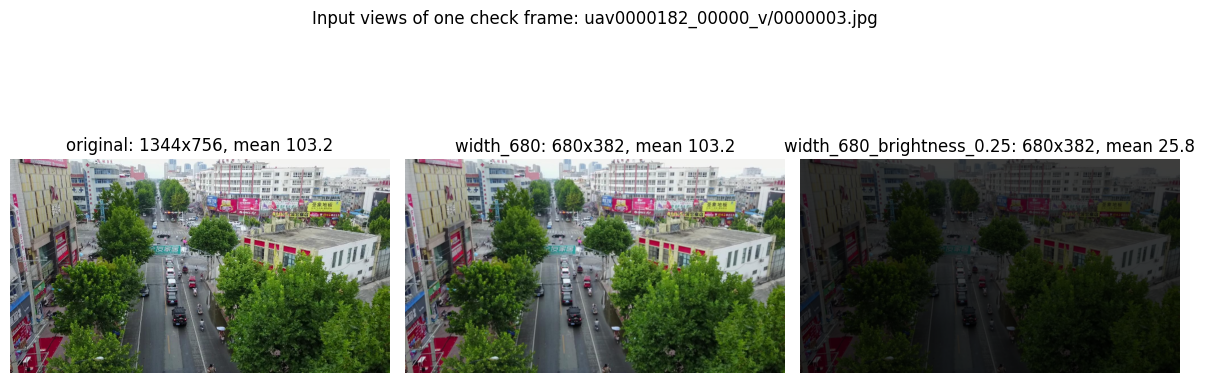

In [12]:
example_path = check_frames.filter(pl.col("clip") == EXAMPLE_CLIP)["path"][0]
example_image = decode_image(example_path, mode=ImageReadMode.RGB)
fig, axes = plt.subplots(1, len(EXAMPLE_VIEWS), figsize=FIGURE_SIZE)
example_rows = []
for ax, view_name in zip(axes, EXAMPLE_VIEWS, strict=True):
    view = build_view(example_image, *VIEW_SETTINGS[view_name])
    pixels, _ = downscale_for_display(view)
    mean_value = round(float(view.float().mean()), 1)
    ax.imshow(pixels)
    ax.set_title(f"{view_name}: {view.shape[-1]}x{view.shape[-2]}, mean {mean_value}")
    ax.axis("off")
    example_rows.append(
        {"view": view_name, "width": view.shape[-1], "height": view.shape[-2], "mean_value": mean_value}
    )
fig.suptitle(f"Input views of one check frame: {to_frame_key(example_path)}")
save_figure(fig, "view_examples", pl.DataFrame(example_rows))

## Training

Nothing is trained: this section runs the predictions. `predict_view` decodes each check frame, builds the view, and passes the chunk to Ultralytics as BGR arrays with `imgsz = IMAGE_SIZE`, `conf = CONF_THRESHOLD`, `max_det = MAX_DETECTIONS`, fp32 on `DEVICE`. Ultralytics returns boxes in the coordinates of the view; they are multiplied by (original width / view width, original height / view height), clipped to the original frame, and stored with 0-based class ids. The `isinstance` checks narrow the optional and union types of the Ultralytics API and fail loudly if they do not hold. Timing follows `SPEED_PROTOCOL` (Ultralytics' preprocess + inference + postprocess per image).

In [13]:
type FrameDetections = tuple[np.ndarray, np.ndarray, np.ndarray]


def predict_view(
    model: Model, frame_paths: list[str], width: int | None, brightness: float
) -> tuple[dict[str, FrameDetections], float]:
    detections_by_key: dict[str, FrameDetections] = {}
    milliseconds_per_image = []
    for chunk_start in range(0, len(frame_paths), PREDICT_CHUNK_SIZE):
        chunk_paths = frame_paths[chunk_start : chunk_start + PREDICT_CHUNK_SIZE]
        images = [decode_image(path, mode=ImageReadMode.RGB) for path in chunk_paths]
        views = [build_view(image, width, brightness) for image in images]
        results = model.predict(
            source=[to_bgr_array(view) for view in views],
            batch=PREDICT_CHUNK_SIZE,
            imgsz=IMAGE_SIZE,
            conf=CONF_THRESHOLD,
            max_det=MAX_DETECTIONS,
            half=False,
            device=DEVICE,
            verbose=False,
        )
        for path, image, view, result in zip(chunk_paths, images, views, results, strict=True):
            if not isinstance(result, Results) or result.boxes is None:
                raise RuntimeError(f"Unexpected prediction for {path}")
            xyxy = result.boxes.xyxy
            confidence = result.boxes.conf
            class_tensor = result.boxes.cls
            if not (
                isinstance(xyxy, torch.Tensor)
                and isinstance(confidence, torch.Tensor)
                and isinstance(class_tensor, torch.Tensor)
            ):
                raise RuntimeError(f"Unexpected box tensors for {path}")
            image_height, image_width = image.shape[-2:]
            view_height, view_width = view.shape[-2:]
            scale = np.array([image_width / view_width, image_height / view_height] * 2, dtype=np.float32)
            image_bounds = np.array([image_width, image_height] * 2, dtype=np.float32)
            detections_by_key[to_frame_key(path)] = (
                (xyxy.cpu().numpy() * scale).clip(0, image_bounds).astype(np.float32),
                confidence.cpu().numpy().astype(np.float32),
                class_tensor.cpu().numpy().astype(np.int64),
            )
            stage_milliseconds = [value for value in result.speed.values() if value is not None]
            if len(stage_milliseconds) != len(result.speed):
                raise RuntimeError(f"Missing Ultralytics timing for {path}")
            milliseconds_per_image.append(sum(stage_milliseconds))
    return detections_by_key, float(np.mean(milliseconds_per_image))

The prediction loop, one view at a time with both models, so that a stop leaves both models with the same views. Before each view after the first, the time guard projects the end of that view from the mean time per view so far and stops if it would pass `MAX_TRAIN_HOURS`; the remaining views are listed in `skipped_views`. One line per view.

In [14]:
detections_by_row: dict[tuple[str, str], dict[str, FrameDetections]] = {}
ms_per_image_by_row: dict[tuple[str, str], float] = {}
skipped_views: list[str] = []
view_names = list(VIEW_SETTINGS)
prediction_started = time.time()
for view_index, view_name in enumerate(view_names):
    elapsed_hours = (time.time() - prediction_started) / 3600
    if view_index > 0 and elapsed_hours + elapsed_hours / view_index > MAX_TRAIN_HOURS:
        skipped_views = view_names[view_index:]
        break
    for model_label, model in model_by_label.items():
        detections_by_key, ms_per_image = predict_view(model, check_paths, *VIEW_SETTINGS[view_name])
        detections_by_row[(model_label, view_name)] = detections_by_key
        ms_per_image_by_row[(model_label, view_name)] = ms_per_image
    elapsed_minutes = (time.time() - prediction_started) / 60
    speeds = " | ".join(f"{label} {ms_per_image_by_row[(label, view_name)]:.0f} ms/image" for label in model_by_label)
    print(f"view {view_index + 1}/{len(view_names)} {view_name} | {elapsed_minutes:.0f} min | {speeds}", flush=True)
prediction_hours = (time.time() - prediction_started) / 3600
evaluated_views = [view_name for view_name in view_names if view_name not in skipped_views]

view 1/6 original | 2 min | C4 44 ms/image | T7 43 ms/image
view 2/6 width_960 | 3 min | C4 40 ms/image | T7 39 ms/image
view 3/6 width_680 | 5 min | C4 39 ms/image | T7 39 ms/image
view 4/6 brightness_0.5 | 8 min | C4 46 ms/image | T7 46 ms/image
view 5/6 brightness_0.25 | 11 min | C4 46 ms/image | T7 46 ms/image
view 6/6 width_680_brightness_0.25 | 12 min | C4 40 ms/image | T7 39 ms/image


## Validation

Every model × view row is evaluated with our COCOeval on the 571 check frames, and again without the 4K clip. The helpers are copied from the single-run notebooks: conversion to the COCO results format (`category_id = class + 1`, bbox `[x, y, w, h]` rounded to 2 decimals, score to 4) and COCOeval at `maxDets = [1, 100, 500]` restricted to the given image ids. `COCO.loadRes` mutates its input, so `evaluate_coco` passes copies, and the precision array is checked explicitly before slicing.

In [15]:
def to_coco_results(
    detections_by_key: dict[str, FrameDetections], image_id_by_key: dict[str, int]
) -> list[dict[str, object]]:
    return [
        {
            "image_id": image_id_by_key[key],
            "category_id": int(class_id) + 1,
            "bbox": [round(x1, 2), round(y1, 2), round(x2 - x1, 2), round(y2 - y1, 2)],
            "score": round(score, 4),
        }
        for key, (boxes, scores, class_ids) in detections_by_key.items()
        for (x1, y1, x2, y2), score, class_id in zip(boxes.tolist(), scores.tolist(), class_ids.tolist(), strict=True)
    ]


def evaluate_coco(
    ground_truth: COCO, detections: list[dict[str, object]], image_ids: list[int] | None = None
) -> COCOeval:
    with contextlib.redirect_stdout(io.StringIO()):
        evaluator = COCOeval(ground_truth, ground_truth.loadRes([dict(item) for item in detections]), "bbox")
        evaluator.params.maxDets = [1, 100, MAX_DETECTIONS]
        if image_ids is not None:
            evaluator.params.imgIds = image_ids
        evaluator.evaluate()
        evaluator.accumulate()
        evaluator.summarize()
    return evaluator


def read_precision_at_max_detections(evaluator: COCOeval) -> np.ndarray:
    precision = evaluator.eval["precision"]
    if not isinstance(precision, np.ndarray):
        raise RuntimeError("COCOeval has no precision array; call accumulate() first")
    return precision[:, :, :, 0, -1]


def compute_map_at_max_detections(evaluator: COCOeval) -> float:
    precision = read_precision_at_max_detections(evaluator)
    return float(np.mean(precision[precision > -1]))


def round_valid_metric(value: float) -> float | None:
    return round(float(value), 4) if value > -1 else None


def select_predictions(predictions: list[dict[str, object]], image_ids: list[int]) -> list[dict[str, object]]:
    image_id_set = set(image_ids)
    return [item for item in predictions if item["image_id"] in image_id_set]


coco_results_by_row = {
    row: to_coco_results(detections_by_key, val_image_id_by_key) for row, detections_by_key in detections_by_row.items()
}

Robustness table, written to `robustness.csv`. How to read this table: one row per model and view, on the 571 check frames. `mAP` is AP@[.50:.95] at 500 detections per frame; `AP_small`, `AP_medium` and `AP_large` use COCO's 32² / 96² buckets in original pixels; `AR500` is the average recall at 500 detections per frame; `mAP_without_4k` leaves out the 196 frames of `uav0000268_05773_v`. The `delta_*` columns subtract the same model's `original` row, so they show what the view costs that model. `ms_per_image` is the time per frame of that row (`SPEED_PROTOCOL`).

In [16]:
robustness_rows = []
for (model_label, view_name), predictions in coco_results_by_row.items():
    evaluator = evaluate_coco(val_ground_truth, predictions, check_image_ids)
    evaluator_without_four_k = evaluate_coco(
        val_ground_truth,
        select_predictions(predictions, check_image_ids_without_four_k),
        check_image_ids_without_four_k,
    )
    robustness_rows.append(
        {
            "model": model_label,
            "view": view_name,
            "mAP": round(compute_map_at_max_detections(evaluator), 4),
            "AP50": round_valid_metric(evaluator.stats[1]),
            "AP_small": round_valid_metric(evaluator.stats[3]),
            "AP_medium": round_valid_metric(evaluator.stats[4]),
            "AP_large": round_valid_metric(evaluator.stats[5]),
            "AR500": round_valid_metric(evaluator.stats[8]),
            "mAP_without_4k": round(compute_map_at_max_detections(evaluator_without_four_k), 4),
            "ms_per_image": round(ms_per_image_by_row[(model_label, view_name)], 1),
        }
    )
robustness = pl.DataFrame(robustness_rows).with_columns(
    [
        (pl.col(name) - pl.col(name).filter(pl.col("view") == REFERENCE_VIEW).first().over("model"))
        .round(4)
        .alias(f"delta_{name}_vs_original")
        for name in ["mAP", "AP_small", "mAP_without_4k"]
    ]
)
robustness.write_csv(OUTPUT_DIR / "robustness.csv")
robustness

model,view,mAP,AP50,AP_small,AP_medium,AP_large,AR500,mAP_without_4k,ms_per_image,delta_mAP_vs_original,delta_AP_small_vs_original,delta_mAP_without_4k_vs_original
str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""C4""","""original""",0.2403,0.4566,0.1236,0.2039,0.4134,0.3964,0.2648,44.0,0.0,0.0,0.0
"""T7""","""original""",0.2142,0.4263,0.1173,0.2096,0.3447,0.3605,0.2458,43.3,0.0,0.0,0.0
"""C4""","""width_960""",0.2251,0.4332,0.1238,0.1915,0.3808,0.3739,0.2534,39.7,-0.0152,0.0002,-0.0114
"""T7""","""width_960""",0.2024,0.3996,0.1251,0.1937,0.3291,0.3395,0.2348,39.4,-0.0118,0.0078,-0.011
"""C4""","""width_680""",0.2065,0.4009,0.1123,0.1729,0.3657,0.3585,0.2314,39.1,-0.0338,-0.0113,-0.0334
…,…,…,…,…,…,…,…,…,…,…,…,…
"""T7""","""brightness_0.5""",0.2042,0.4128,0.1169,0.2063,0.3195,0.3496,0.2335,46.2,-0.01,-0.0004,-0.0123
"""C4""","""brightness_0.25""",0.22,0.4239,0.1247,0.1962,0.3822,0.3733,0.241,46.1,-0.0203,0.0011,-0.0238
"""T7""","""brightness_0.25""",0.1714,0.3531,0.1136,0.1791,0.2614,0.3037,0.1933,46.2,-0.0428,-0.0037,-0.0525


Gap between the models per view, written to `robustness_model_gap.csv`. How to read this table: one row per view; every `*_gap` column is the `REFERENCE_MODEL` value minus the other model's value (C4 − T7). `mAP_gap` in the `original` row is the gap on unchanged frames; `delta_mAP_vs_original_gap` is how much more (positive) or less (negative) C4 keeps of its own `original` score than T7 does in that view.

In [17]:
comparison_model = next(model_label for model_label in KERNEL_BY_MODEL if model_label != REFERENCE_MODEL)
gap_columns = ["mAP", "AP_small", "mAP_without_4k", "delta_mAP_vs_original", "delta_mAP_without_4k_vs_original"]
model_gap = (
    robustness.filter(pl.col("model") == REFERENCE_MODEL)
    .select("view", *gap_columns)
    .join(
        robustness.filter(pl.col("model") == comparison_model).select("view", *gap_columns),
        on="view",
        suffix="_comparison",
        maintain_order="left",
    )
    .select(
        "view",
        *[(pl.col(name) - pl.col(f"{name}_comparison")).round(4).alias(f"{name}_gap") for name in gap_columns],
    )
)
model_gap.write_csv(OUTPUT_DIR / "robustness_model_gap.csv")
model_gap

view,mAP_gap,AP_small_gap,mAP_without_4k_gap,delta_mAP_vs_original_gap,delta_mAP_without_4k_vs_original_gap
str,f64,f64,f64,f64,f64
"""original""",0.0261,0.0063,0.019,0.0,0.0
"""width_960""",0.0227,-0.0013,0.0186,-0.0034,-0.0004
"""width_680""",0.0271,0.0189,0.022,0.001,0.003
"""brightness_0.5""",0.0251,0.0081,0.0196,-0.001,0.0006
"""brightness_0.25""",0.0486,0.0111,0.0477,0.0225,0.0287
"""width_680_brightness_0.25""",0.0578,0.0147,0.0584,0.0317,0.0394


Per-clip AP for every model and view, written to `robustness_per_clip.csv` in long format and shown as a wide table. How to read this table: one row per model and view, one column per val clip; each value is AP@[.50:.95] at 500 detections per frame on that clip's check frames alone. The clips have different native widths (1344 to 3840 px, `EDA.md` §5), so a `width_*` view shrinks them by different factors.

In [18]:
per_clip_rows = []
for (model_label, view_name), predictions in coco_results_by_row.items():
    for clip, image_ids in check_image_ids_by_clip.items():
        evaluator = evaluate_coco(val_ground_truth, select_predictions(predictions, image_ids), image_ids)
        per_clip_rows.append(
            {
                "model": model_label,
                "view": view_name,
                "clip": clip,
                "frames": len(image_ids),
                "AP": round(compute_map_at_max_detections(evaluator), 4),
                "AP_small": round_valid_metric(evaluator.stats[3]),
            }
        )
robustness_per_clip = pl.DataFrame(per_clip_rows)
robustness_per_clip.write_csv(OUTPUT_DIR / "robustness_per_clip.csv")
robustness_per_clip.pivot(on="clip", index=["model", "view"], values="AP")

model,view,uav0000086_00000_v,uav0000117_02622_v,uav0000137_00458_v,uav0000182_00000_v,uav0000268_05773_v,uav0000305_00000_v,uav0000339_00001_v
str,str,f64,f64,f64,f64,f64,f64,f64
"""C4""","""original""",0.1949,0.259,0.2948,0.1983,0.1346,0.2441,0.2891
"""T7""","""original""",0.2774,0.2437,0.3202,0.1881,0.0673,0.2466,0.2517
"""C4""","""width_960""",0.1772,0.2362,0.2893,0.199,0.0683,0.2413,0.2762
"""T7""","""width_960""",0.2878,0.2268,0.301,0.1771,0.0505,0.1989,0.2654
"""C4""","""width_680""",0.1802,0.2086,0.2751,0.1771,0.0677,0.2398,0.2593
…,…,…,…,…,…,…,…,…
"""T7""","""brightness_0.5""",0.2895,0.2141,0.3272,0.1816,0.0769,0.2204,0.2598
"""C4""","""brightness_0.25""",0.1994,0.2086,0.2952,0.1865,0.1415,0.2458,0.2848
"""T7""","""brightness_0.25""",0.2743,0.124,0.3093,0.161,0.0825,0.1603,0.2363


Figure: mAP@500 on the check frames for every evaluated view, one bar per model. The CSV holds the plotted values with AP_small and the deltas.

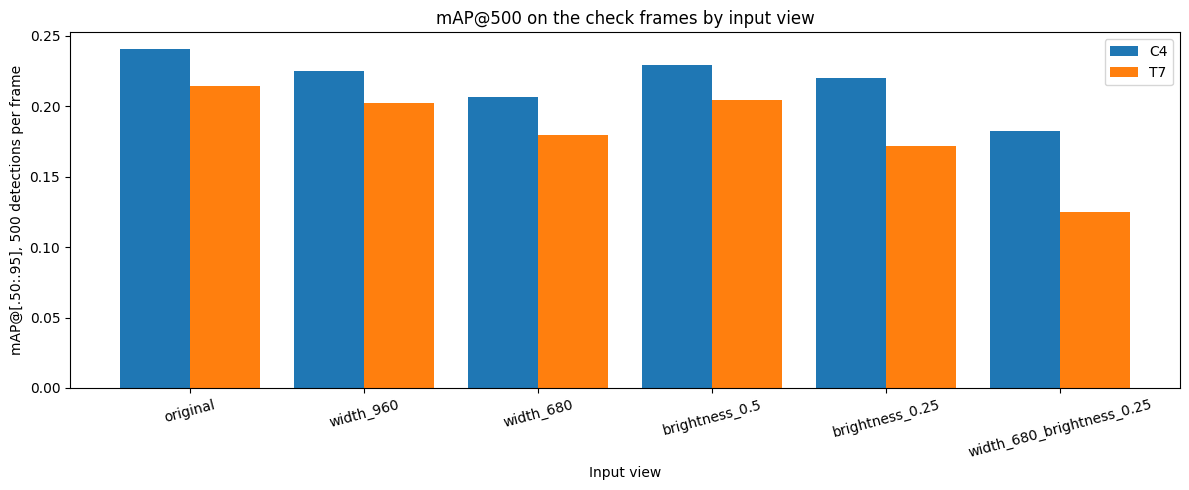

In [19]:
map_by_row = {
    (model_label, view_name): value
    for model_label, view_name, value in robustness.select("model", "view", "mAP").iter_rows()
}
positions = np.arange(len(evaluated_views))
bar_width = 0.8 / len(model_by_label)
fig, ax = plt.subplots(figsize=FIGURE_SIZE)
for model_index, model_label in enumerate(model_by_label):
    ax.bar(
        positions + model_index * bar_width,
        [map_by_row[(model_label, view_name)] for view_name in evaluated_views],
        width=bar_width,
        label=model_label,
    )
ax.set_xticks(positions + bar_width * (len(model_by_label) - 1) / 2, evaluated_views, rotation=15)
ax.set_title("mAP@500 on the check frames by input view")
ax.set_xlabel("Input view")
ax.set_ylabel("mAP@[.50:.95], 500 detections per frame")
ax.legend()
save_figure(fig, "robustness", robustness.select("model", "view", "mAP", "AP_small", "delta_mAP_vs_original"))

Required output `val_predictions.json`: no new detector is evaluated on full val here, so the file is an unchanged copy of the full-val detections of `REFERENCE_MODEL` (C4) from its kernel.

In [20]:
shutil.copyfile(
    read_source_file(KERNEL_BY_MODEL[REFERENCE_MODEL], "val_predictions.json"), OUTPUT_DIR / "val_predictions.json"
)
copied_megabytes = (OUTPUT_DIR / "val_predictions.json").stat().st_size / 2**20
print(f"val_predictions.json copied from {KERNEL_BY_MODEL[REFERENCE_MODEL]} | {copied_megabytes:.1f} MiB")

val_predictions.json copied from dmnk1304/yolo11s-p2-combined | 128.0 MiB


`result.json` writer: the core keys are checked before writing. Keys that do not apply to an inference-only check are `null`: the epoch, batch, learning-rate and training-frame keys, and the eight core metrics, because the check runs on 571 frames under changed inputs and its numbers are not full-val metrics of a detector. `val_frames` is the number of check frames, `ms_per_image` is the time per frame of the `REFERENCE_MODEL` `original` row, and `train_hours` is the wall-clock time of the prediction loop (GPU inference, no training). The robustness rows, the model gap and the view settings are extra keys.

In [21]:
REQUIRED_RESULT_KEYS = [
    "run",
    "notebook",
    "model",
    "family",
    "variant",
    "parent_run",
    "changed_params",
    "seed",
    "imgsz",
    "epochs_planned",
    "epochs_run",
    "best_epoch",
    "batch",
    "lr",
    "train_frames",
    "val_frames",
    "frame_step",
    "ignore_strategy",
    "mAP",
    "mAP_maxdet100",
    "AP50",
    "AP75",
    "AP_small",
    "AP_medium",
    "AP_large",
    "AR500",
    "ms_per_image",
    "speed_protocol",
    "train_hours",
    "gpu_name",
    "versions",
    "started_at",
    "finished_at",
]
FAMILIES = ["two_stage", "one_stage_anchor", "anchor_free", "query", "pipeline"]
VARIANTS = ["initial", "tuned"]


def write_result(result: dict[str, object]) -> None:
    missing_keys = [key for key in REQUIRED_RESULT_KEYS if key not in result]
    if missing_keys:
        raise ValueError(f"result.json is missing core keys: {missing_keys}")
    if result["family"] not in FAMILIES or result["variant"] not in VARIANTS:
        raise ValueError(f"Invalid family or variant: {result['family']}, {result['variant']}")
    (OUTPUT_DIR / "result.json").write_text(json.dumps(result, indent=2))

The run summary, shown as a one-row table (without the list and dict entries).

In [22]:
result: dict[str, object] = {
    "run": RUN_NAME,
    "notebook": f"new-notebooks/{RUN_NAME}.ipynb",
    "model": MODEL_NAME,
    "family": FAMILY,
    "variant": VARIANT,
    "parent_run": PARENT_RUN,
    "changed_params": CHANGED_PARAMS,
    "seed": SEED,
    "imgsz": IMAGE_SIZE,
    "epochs_planned": None,
    "epochs_run": None,
    "best_epoch": None,
    "batch": None,
    "lr": None,
    "train_frames": None,
    "val_frames": check_frames.height,
    "frame_step": None,
    "ignore_strategy": IGNORE_STRATEGY,
    "mAP": None,
    "mAP_maxdet100": None,
    "AP50": None,
    "AP75": None,
    "AP_small": None,
    "AP_medium": None,
    "AP_large": None,
    "AR500": None,
    "ms_per_image": round(ms_per_image_by_row[(REFERENCE_MODEL, REFERENCE_VIEW)], 1),
    "speed_protocol": SPEED_PROTOCOL,
    "train_hours": round(prediction_hours, 2),
    "gpu_name": gpu_name,
    "versions": package_versions,
    "started_at": started_at,
    "finished_at": datetime.now(UTC).isoformat(timespec="seconds"),
    "device": DEVICE,
    "source_kernels": list(SOURCE_KERNELS),
    "kernel_by_model": KERNEL_BY_MODEL,
    "reference_model": REFERENCE_MODEL,
    "copied_from_reference_model": ["val_predictions.json", "submission.csv"],
    "check_frame_offset": CHECK_FRAME_OFFSET,
    "view_settings": {name: {"width": width, "brightness": factor} for name, (width, factor) in VIEW_SETTINGS.items()},
    "skipped_views": skipped_views,
    "robustness": robustness.to_dicts(),
    "model_gap": model_gap.to_dicts(),
}
write_result(result)
pl.DataFrame(
    [{key: value for key, value in result.items() if value is not None and not isinstance(value, list | dict)}]
)

run,notebook,model,family,variant,parent_run,seed,imgsz,val_frames,ignore_strategy,ms_per_image,speed_protocol,train_hours,gpu_name,started_at,finished_at,device,reference_model,check_frame_offset
str,str,str,str,str,str,i64,i64,i64,str,f64,str,f64,str,str,str,i64,str,i64
"""yolo11s-p2-robustness""","""new-notebooks/yolo11s-p2-robus…","""robustness check of the saved …","""pipeline""","""tuned""","""yolo11s-p2-combined""",42,1280,571,"""per_image_mean_fill""",44.0,"""Ultralytics result.speed prepr…",0.21,"""Tesla T4""","""2026-11-07T14:33:47+00:00""","""2026-11-07T15:28:00+00:00""",0,"""C4""",2


## Submission

Required output `submission.csv`: no new detector is produced here, so the file is an unchanged copy of the `submission.csv` of `REFERENCE_MODEL` (C4, public LB 0.28689). It is not a new submission.

In [23]:
test_images = pl.read_csv(DATA_ROOT / "test_images.csv")
require_count("test frames", test_images.height, EXPECTED_TEST_FRAMES)
shutil.copyfile(read_source_file(KERNEL_BY_MODEL[REFERENCE_MODEL], "submission.csv"), OUTPUT_DIR / "submission.csv")
print(f"submission.csv copied from {KERNEL_BY_MODEL[REFERENCE_MODEL]}")

submission.csv copied from dmnk1304/yolo11s-p2-combined


Format checks on the copied file as it is on disk, against `test_images.csv` and the fixed columns `image_id,PredictionString` (the competition data has no `sample_submission.csv`). The results go to `submission_check.json`, and the notebook raises if any check fails.

In [24]:
SUBMISSION_COLUMNS = ["image_id", "PredictionString"]
SUBMISSION_FIELDS = ["class_id", "score", "x", "y", "w", "h"]


def check_submission(submission: pl.DataFrame, test_images: pl.DataFrame) -> dict[str, bool]:
    groups = (
        submission.join(test_images.select("image_id", "width", "height"), on="image_id", how="left")
        .filter(pl.col("PredictionString") != "")
        .with_columns(values=pl.col("PredictionString").str.split(" ").cast(pl.List(pl.Float64)))
    )
    boxes = groups.select(
        "width",
        "height",
        *[pl.col("values").list.gather_every(6, offset).alias(name) for offset, name in enumerate(SUBMISSION_FIELDS)],
    ).explode(SUBMISSION_FIELDS)
    return {
        "columns_match_submission_format": submission.columns == SUBMISSION_COLUMNS,
        "image_ids_match_test_images_order": submission["image_id"].equals(test_images["image_id"]),
        "image_ids_unique": bool(submission["image_id"].is_unique().all()),
        "values_multiple_of_six": bool(groups.select((pl.col("values").list.len() % 6 == 0).all()).item()),
        "at_most_max_detections_per_image": bool(
            groups.select((pl.col("values").list.len() <= 6 * MAX_DETECTIONS).all()).item()
        ),
        "class_ids_are_valid_integers": bool(
            boxes.select(
                (
                    pl.col("class_id").is_between(0, len(CLASSES) - 1)
                    & (pl.col("class_id") == pl.col("class_id").floor())
                ).all()
            ).item()
        ),
        "scores_in_unit_interval": bool(boxes["score"].is_between(0, 1).all()),
        "sizes_positive": bool(boxes.select(((pl.col("w") > 0) & (pl.col("h") > 0)).all()).item()),
        "boxes_inside_image": bool(
            boxes.select(
                (
                    (pl.col("x") >= -1)
                    & (pl.col("y") >= -1)
                    & (pl.col("x") + pl.col("w") <= pl.col("width") + 1)
                    & (pl.col("y") + pl.col("h") <= pl.col("height") + 1)
                ).all()
            ).item()
        ),
    }


submission_on_disk = pl.read_csv(
    OUTPUT_DIR / "submission.csv", schema={"image_id": pl.String, "PredictionString": pl.String}
).with_columns(pl.col("PredictionString").fill_null(""))
submission_check = check_submission(submission_on_disk, test_images)
(OUTPUT_DIR / "submission_check.json").write_text(json.dumps(submission_check, indent=2))
failed_checks = [name for name, is_passed in submission_check.items() if not is_passed]
if failed_checks:
    raise ValueError(f"Submission checks failed: {failed_checks}")
submission_check

{'columns_match_submission_format': True,
 'image_ids_match_test_images_order': True,
 'image_ids_unique': True,
 'values_multiple_of_six': True,
 'at_most_max_detections_per_image': True,
 'class_ids_are_valid_integers': True,
 'scores_in_unit_interval': True,
 'sizes_positive': True,
 'boxes_inside_image': True}

## References

- Ultralytics YOLO11, model loading and the prediction API (`ultralytics==8.4.193`), AGPL-3.0: https://github.com/ultralytics/ultralytics; prediction arguments and accepted sources (numpy arrays in BGR order): https://docs.ultralytics.com/modes/predict/
- Ultralytics `hsv_v` and `scale` augmentation arguments (the training settings of C4 that this check probes), AGPL-3.0: https://docs.ultralytics.com/usage/cfg/
- torchvision `torchvision.io.decode_image` and `torchvision.transforms.v2.functional.resize` (antialiased bilinear resize), BSD-3-Clause: https://github.com/pytorch/vision
- pycocotools (COCOeval), BSD-2-Clause: https://github.com/cocodataset/cocoapi
- Lin et al. Microsoft COCO: Common Objects in Context (metric definitions, size buckets). arXiv:1405.0312.
- Zhu et al. Detection and Tracking Meet Drones Challenge (VisDrone, ignored regions). arXiv:2001.06303.
- Source runs: C4 `yolo11s-p2-combined` (`new-notebooks/yolo11s-p2-combined.ipynb`, report `experiments/dmnk1304/yolo11s-p2-combined.md`) and T7 `yolo11s-1280-p2` (`new-notebooks/yolo11s-1280-p2.ipynb`, report `experiments/dmnk1304/yolo11s-1280-p2.md`). Their val and public LB scores and the findings F9, F13, F92–F93 are in `EXPERIMENTS.md` and `SCOPE.md`.
- EDA notebook `notebooks/eda.ipynb` and its summary `EDA.md`: test and val clip resolutions (§5) and clip brightness (§9), the source of the view settings.
- Protocol code (frame listing, COCOeval helpers, result and submission writers, source-kernel reading) is copied from the repository's own notebooks `yolo11s-p2-combined` and `pipeline-temporal`.